my attempt at a rnn for time series data analysis
will come back and improve at some point

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)

EPSILON = 1e-15

In [2]:
def tanh(x):
    return np.tanh(x)

def tanh_derivative(output):
    return 1.0 - output ** 2

ACTIVATIONS = {
    'tanh': (tanh, tanh_derivative),
}

def softmax(x):
    shifted = x - np.max(x)
    exps = np.exp(shifted)
    return exps / np.sum(exps)

def cross_entropy(probs, target):
    return -np.sum(target * np.log(np.maximum(probs, EPSILON)))

In [3]:
class RNN:

    def __init__(self, input_size, hidden_size, output_size, activation="tanh"):
        self.hidden_size = hidden_size

        limit_xh = np.sqrt(6 / (input_size + hidden_size))
        limit_hh = np.sqrt(6 / (hidden_size + hidden_size))
        limit_hy = np.sqrt(6 / (hidden_size + output_size))

        self.Wxh = np.random.uniform(-limit_xh, limit_xh, (hidden_size, input_size))
        self.Whh = np.random.uniform(-limit_hh, limit_hh, (hidden_size, hidden_size))
        self.Why = np.random.uniform(-limit_hy, limit_hy, (output_size, hidden_size))
        self.bh = np.zeros(hidden_size)
        self.by = np.zeros(output_size)

        self.activation, self.derivative = ACTIVATIONS[activation]

        self.xs = None
        self.hs = None
        self.probs = None

    def forward(self, inputs):
        # inputs: (T, input_size)
        T = inputs.shape[0]
        h = np.zeros(self.hidden_size)

        self.hs = [h]
        self.xs = []

        for t in range(T):
            x_t = inputs[t]
            a_t = self.Wxh @ x_t + self.Whh @ h + self.bh
            h = self.activation(a_t)
            self.xs.append(x_t)
            self.hs.append(h)

        logits = self.Why @ h + self.by
        self.probs = softmax(logits)
        return self.probs

    def backward(self, target, clip=5.0):
        target = np.asarray(target, dtype=float)
        T = len(self.xs)

        dWxh = np.zeros_like(self.Wxh)
        dWhh = np.zeros_like(self.Whh)
        dbh = np.zeros_like(self.bh)

        dy = self.probs - target
        dWhy = np.outer(dy, self.hs[-1])
        dby = dy.copy()

        dh_next = self.Why.T @ dy

        for t in reversed(range(T)):
            h_t = self.hs[t + 1]
            h_prev = self.hs[t]
            x_t = self.xs[t]

            da_t = dh_next * self.derivative(h_t)
            dWxh += np.outer(da_t, x_t)
            dWhh += np.outer(da_t, h_prev)
            dbh += da_t

            dh_next = self.Whh.T @ da_t

        for g in (dWxh, dWhh, dWhy, dbh, dby):
            np.clip(g, -clip, clip, out=g)

        self.dWxh, self.dWhh, self.dWhy = dWxh, dWhh, dWhy
        self.dbh, self.dby = dbh, dby

    def update(self, learning_rate=0.05):
        self.Wxh -= learning_rate * self.dWxh
        self.Whh -= learning_rate * self.dWhh
        self.Why -= learning_rate * self.dWhy
        self.bh -= learning_rate * self.dbh
        self.by -= learning_rate * self.dby

In [4]:
# data: daily seattle weather, 2012-01-01 through 2015-12-31
# columns: date, precipitation, temp_max, temp_min, wind, weather

WEATHER_CLASSES = ['drizzle', 'rain', 'sun', 'snow', 'fog']
CLASS_TO_IDX = {c: i for i, c in enumerate(WEATHER_CLASSES)}
FEATURE_COLS = ['precipitation', 'temp_max', 'temp_min', 'wind']
SEQ_LEN = 7   # past week of readings -> predict tomorrow's weather category

df = pd.read_csv("data/seattle_weather.csv", parse_dates=["date"])
df = df.sort_values("date").reset_index(drop=True)

print(f"{len(df)} rows, {df['date'].min().date()} to {df['date'].max().date()}")
print(df["weather"].value_counts())

1461 rows, 2012-01-01 to 2015-12-31
weather
rain       641
sun        640
fog        101
drizzle     53
snow        26
Name: count, dtype: int64


In [5]:
n_total = len(df)
n_train = int(n_total * 0.70)
n_val = int(n_total * 0.15)

train_df = df.iloc[:n_train]
val_df = df.iloc[n_train:n_train + n_val]
test_df = df.iloc[n_train + n_val:]

feat_mean = train_df[FEATURE_COLS].mean().values.copy()
feat_std = train_df[FEATURE_COLS].std().values.copy()
feat_std[feat_std == 0] = 1.0  # guard against a zero-variance column

def one_hot(idx, num_classes=5):
    target = np.zeros(num_classes)
    target[idx] = 1.0
    return target

def make_windows(sub_df, seq_len=SEQ_LEN):
    values = (sub_df[FEATURE_COLS].values - feat_mean) / feat_std
    labels = sub_df["weather"].map(CLASS_TO_IDX).values
    X, Y = [], []
    for i in range(len(sub_df) - seq_len):
        X.append(values[i:i + seq_len])
        Y.append(labels[i + seq_len])
    return np.array(X), np.array(Y)

train_X, train_Y = make_windows(train_df)
val_X, val_Y = make_windows(val_df)
test_X, test_Y = make_windows(test_df)

print(f"train windows: {train_X.shape}  val: {val_X.shape}  test: {test_X.shape}")

train windows: (1015, 7, 4)  val: (212, 7, 4)  test: (213, 7, 4)


In [6]:
def evaluate(model, X, Y):
    correct = 0
    total_loss = 0.0
    for x, y in zip(X, Y):
        probs = model.forward(x)
        target = one_hot(y)
        total_loss += cross_entropy(probs, target)
        if np.argmax(probs) == y:
            correct += 1
    n = max(len(X), 1)
    return total_loss / n, correct / n * 100

In [7]:
epochs = 100
learning_rate = 0.05

model = RNN(input_size=len(FEATURE_COLS), hidden_size=32, output_size=5, activation="tanh")

history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

for epoch in range(epochs):
    perm = np.random.permutation(len(train_X))
    total_loss, correct = 0.0, 0

    for idx in perm:
        x, y = train_X[idx], train_Y[idx]
        probs = model.forward(x)
        target = one_hot(y)

        total_loss += cross_entropy(probs, target)
        if np.argmax(probs) == y:
            correct += 1

        model.backward(target)
        model.update(learning_rate)

    train_loss = total_loss / len(train_X)
    train_acc = correct / len(train_X) * 100
    val_loss, val_acc = evaluate(model, val_X, val_Y)

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    if epoch % 5 == 0 or epoch == epochs - 1:
        print(f"Epoch {epoch:3d} | Train Loss: {train_loss:.4f} Acc: {train_acc:5.1f}% "
              f"| Val Loss: {val_loss:.4f} Acc: {val_acc:5.1f}%")

test_loss, test_acc = evaluate(model, test_X, test_Y)
print(f"\nTest Loss: {test_loss:.4f} | Test Acc: {test_acc:.2f}%")

Epoch   0 | Train Loss: 1.0960 Acc:  56.4% | Val Loss: 1.3591 Acc:  50.0%
Epoch   5 | Train Loss: 0.9625 Acc:  59.7% | Val Loss: 1.2368 Acc:  49.5%
Epoch  10 | Train Loss: 1.0553 Acc:  59.2% | Val Loss: 1.3863 Acc:  49.1%
Epoch  15 | Train Loss: 1.1114 Acc:  58.7% | Val Loss: 1.4130 Acc:  55.7%
Epoch  20 | Train Loss: 1.2102 Acc:  54.0% | Val Loss: 1.3455 Acc:  54.2%
Epoch  25 | Train Loss: 1.2223 Acc:  52.2% | Val Loss: 1.0692 Acc:  49.1%
Epoch  30 | Train Loss: 1.2089 Acc:  54.9% | Val Loss: 1.3188 Acc:  55.7%
Epoch  35 | Train Loss: 1.1976 Acc:  55.7% | Val Loss: 1.5110 Acc:  45.3%
Epoch  40 | Train Loss: 1.1982 Acc:  56.2% | Val Loss: 1.3873 Acc:  53.3%
Epoch  45 | Train Loss: 1.1843 Acc:  56.7% | Val Loss: 1.3444 Acc:  50.5%
Epoch  50 | Train Loss: 1.2079 Acc:  56.2% | Val Loss: 1.3607 Acc:  51.4%
Epoch  55 | Train Loss: 1.1774 Acc:  56.6% | Val Loss: 1.2604 Acc:  50.9%
Epoch  60 | Train Loss: 1.1566 Acc:  57.0% | Val Loss: 1.3621 Acc:  50.9%
Epoch  65 | Train Loss: 1.1441 Acc:  5

In [8]:
y_true, y_pred = [], []
for x, y in zip(test_X, test_Y):
    probs = model.forward(x)
    y_true.append(y)
    y_pred.append(int(np.argmax(probs)))

confusion = np.zeros((5, 5), dtype=int)
for t, p in zip(y_true, y_pred):
    confusion[t, p] += 1

print(f"{'':10s}" + "".join(f"{c:>9s}" for c in WEATHER_CLASSES) + "   (predicted)")
for i, row_label in enumerate(WEATHER_CLASSES):
    print(f"{row_label:10s}" + "".join(f"{confusion[i, j]:9d}" for j in range(5)))

print("\nPer-class recall (of the days that were truly this class, % predicted correctly):")
for i, cls in enumerate(WEATHER_CLASSES):
    support = confusion[i].sum()
    recall = confusion[i, i] / support * 100 if support > 0 else float("nan")
    print(f"  {cls:8s}  support={support:3d}  recall={recall:5.1f}%")

            drizzle     rain      sun     snow      fog   (predicted)
drizzle           0        0        7        0        0
rain              0       39       33        7        0
sun               0       12       87        2        0
snow              0        0        0        0        0
fog               0        9       17        0        0

Per-class recall (of the days that were truly this class, % predicted correctly):
  drizzle   support=  7  recall=  0.0%
  rain      support= 79  recall= 49.4%
  sun       support=101  recall= 86.1%
  snow      support=  0  recall=  nan%
  fog       support= 26  recall=  0.0%


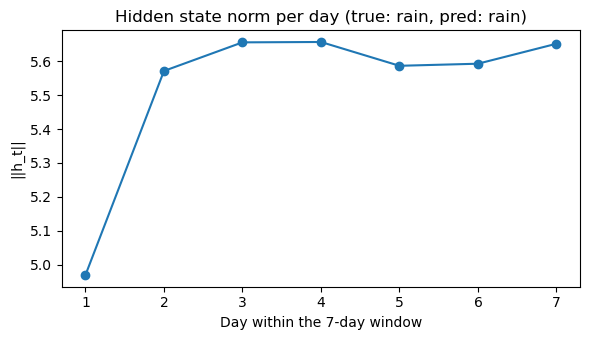

In [9]:
def visualize_hidden_trace(model, x_window, true_idx):
    probs = model.forward(x_window)
    hidden_states = np.array(model.hs[1:])
    hidden_norms = np.linalg.norm(hidden_states, axis=1)

    fig, ax = plt.subplots(figsize=(6, 3.5))
    ax.plot(range(1, SEQ_LEN + 1), hidden_norms, marker="o")
    ax.set_title(
        f"Hidden state norm per day (true: {WEATHER_CLASSES[true_idx]}, "
        f"pred: {WEATHER_CLASSES[np.argmax(probs)]})"
    )
    ax.set_xlabel("Day within the 7-day window")
    ax.set_ylabel("||h_t||")
    plt.tight_layout()
    plt.show()

sample_idx = np.random.randint(len(test_X))
visualize_hidden_trace(model, test_X[sample_idx], test_Y[sample_idx])

Test accuracy 59.2%, above the 47.4% from always predicting “sun”. Rain recall is 49%, but drizzle and fog are never predicted (0% recall). Training is unstable: training loss rises from 1.10 to 1.16 over training and validation accuracy swings between 37% and 60%. With the same seed, an earlier run on a different setup scored 46%, below the baseline, so a single run’s number isn’t reliable yet.